EXPLAINABILITY + ERROR ANALYSIS

This is one of the most important stages.

Instead of asking:

"What is my accuracy?"

we ask:

"Why does the model make mistakes?"

We'll analyze:

False positives
False negatives
highest-confidence fraud
highest-confidence genuine
feature importance
SHAP explanations

STAGE 13 — EXPLAINABILITY + ERROR ANALYSIS

Error counts:
ErrorType
Correct           28358
False Negative       12
False Positive        3
Name: count, dtype: int64

False positives:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,Hour,Actual,Probability,Prediction,ErrorType
274771,166198.0,-35.548539,-31.850484,-48.325589,15.304184,-113.743307,73.301626,120.589494,-27.347360,-3.872425,...,4.554683,3.415636,31.612198,-15.430084,25691.16,22.166111,0,0.732557,1,False Positive
187657,127631.0,1.813886,0.381837,-4.023519,1.046436,1.584362,-0.344732,0.177102,0.088170,1.196258,...,0.653695,-0.187299,0.064843,0.069528,107.50,11.453056,0,0.301453,1,False Positive
8625,11641.0,-0.504072,3.923139,-5.850403,3.445290,5.058796,1.713523,0.875245,1.266811,-1.786064,...,1.059154,0.406180,-0.263793,-0.081023,1.00,3.233611,0,0.223002,1,False Positive



False negatives:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,Hour,Actual,Probability,Prediction,ErrorType
68633,53076.0,1.296231,0.417447,0.193963,0.901644,0.130531,-0.371634,0.158126,-0.202669,-0.079512,...,0.671540,-0.413518,0.032838,0.020600,1.18,14.743333,1,6.642469e-07,0,False Negative
72757,54846.0,-2.986466,-0.000891,0.605887,0.338338,0.685448,-1.581954,0.504206,-0.233403,0.636768,...,0.448552,0.193490,1.214588,-0.013923,1.79,15.235000,1,3.170868e-06,0,False Negative
274382,165981.0,-5.766879,-8.402154,0.056543,6.950983,9.880564,-5.773192,-5.748879,0.721743,-1.076274,...,-1.890041,-0.120803,0.073269,0.583799,0.00,22.105833,1,1.401904e-05,0,False Negative
52521,45501.0,1.001992,0.047938,-0.349002,1.493958,0.186939,0.190966,-0.001112,0.147140,0.580415,...,0.456090,-0.453206,0.046627,0.064698,105.99,12.639167,1,1.585032e-05,0,False Negative
249239,154309.0,-0.082983,-3.935919,-2.616709,0.163310,-1.400952,-0.809419,1.501580,-0.471000,1.519743,...,-0.071622,-1.125881,-0.170947,0.126221,1096.99,18.863611,1,3.013820e-05,0,False Negative
101509,67857.0,-1.739334,-1.304655,0.314103,0.053740,-0.058696,0.071260,0.694862,-0.313270,-0.649377,...,-0.001640,-0.495162,0.031633,0.066280,320.00,18.849167,1,1.151764e-04,0,False Negative
58761,48533.0,1.243848,0.524526,-0.538884,1.209196,0.479538,-0.197429,0.049166,0.037792,0.128119,...,0.681953,-0.194419,0.045917,0.040136,1.00,13.481389,1,2.222444e-04,0,False Negative
154286,101051.0,-1.465316,-1.093377,-0.059768,1.064785,11.095089,-5.430971,-9.378025,-0.446456,1.992110,...,-3.536716,-0.592965,0.675525,0.424849,0.92,4.069722,1,4.117407e-04,0,False Negative
68067,52814.0,-1.101847,-1.632441,0.901067,0.847753,-1.249091,0.654937,1.448868,0.023308,-0.136742,...,-0.300896,0.699175,-0.336072,-0.177587,519.90,14.670556,1,6.156416e-03,0,False Negative
240222,150494.0,1.852889,1.069593,-1.776101,4.617410,0.770413,-0.400859,-0.040970,0.089510,-0.217705,...,0.058063,0.148263,0.042278,0.040573,1.00,17.803889,1,3.002477e-02,0,False Negative



Generating SHAP summary...


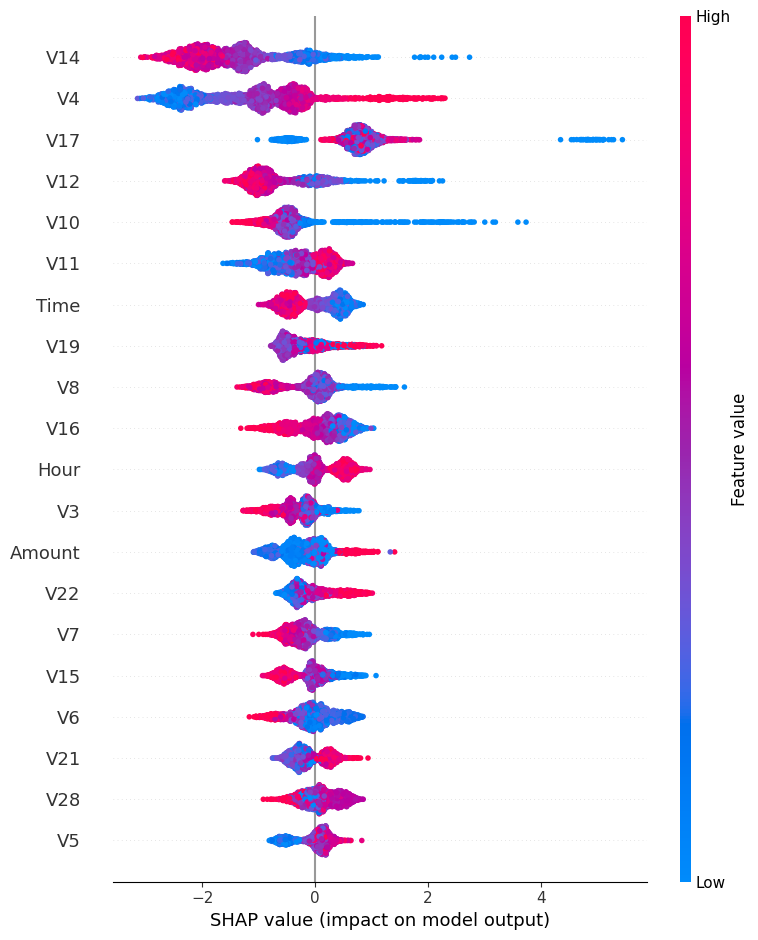

In [93]:
# ================================================================
# STAGE 13 — EXPLAINABILITY + ERROR ANALYSIS
# ================================================================

!pip -q install shap

import shap
import numpy as np
import pandas as pd

print("=" * 70)
print("STAGE 13 — EXPLAINABILITY + ERROR ANALYSIS")
print("=" * 70)

# ------------------------------------------------
# Choose current best supervised model
# ------------------------------------------------

final_validation_proba = optimized_val_proba

threshold = 0.18

final_validation_pred = (
    final_validation_proba >= threshold
).astype(int)

# ------------------------------------------------
# Error analysis
# ------------------------------------------------

error_df = X_val.copy()

error_df["Actual"] = y_val.values
error_df["Probability"] = final_validation_proba
error_df["Prediction"] = final_validation_pred

error_df["ErrorType"] = "Correct"

error_df.loc[
    (error_df["Actual"] == 0) &
    (error_df["Prediction"] == 1),
    "ErrorType"
] = "False Positive"

error_df.loc[
    (error_df["Actual"] == 1) &
    (error_df["Prediction"] == 0),
    "ErrorType"
] = "False Negative"

print("\nError counts:")
print(
    error_df["ErrorType"].value_counts()
)

# ------------------------------------------------
# False positives
# ------------------------------------------------

false_positives = error_df[
    error_df["ErrorType"] == "False Positive"
].sort_values(
    "Probability",
    ascending=False
)

print("\nFalse positives:")
display(
    false_positives.head(10)
)

# ------------------------------------------------
# False negatives
# ------------------------------------------------

false_negatives = error_df[
    error_df["ErrorType"] == "False Negative"
].sort_values(
    "Probability",
    ascending=True
)

print("\nFalse negatives:")
display(
    false_negatives.head(10)
)

# ------------------------------------------------
# SHAP
# ------------------------------------------------

sample_size = min(
    3000,
    len(X_val)
)

X_shap = X_val.sample(
    sample_size,
    random_state=42
)

explainer = shap.TreeExplainer(
    best_xgb
)

shap_values = explainer.shap_values(
    X_shap
)

print("\nGenerating SHAP summary...")

shap.summary_plot(
    shap_values,
    X_shap,
    max_display=20
)